In [1]:
# 1) importando libs
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

In [2]:
# 2) extraindo os .csv (base tratada)
pasta = "database/"
motos = pd.read_csv(pasta + "motos.csv")
clientes = pd.read_csv(pasta + "clientes.csv")
locacoes = pd.read_csv(pasta + "locacoes.csv")
manutencoes = pd.read_csv(pasta + "manutencoes.csv")
locacoes.head()

,id_locacao,id_moto,id_cliente,data_retirada,data_devolucao_prevista,data_devolucao_real,plano,valor_diaria,valor_total,forma_pagamento,status_pagamento,km_retirada,km_devolucao,filial_retirada,status_locacao
0,L00001,M015,C0327,30/06/2023,14/07/2023,14/07/2023,Semanal,76.50,1071.00,Dinheiro,Pago,7190,8884.0,São Paulo,Finalizada
1,L00002,M090,C0331,14/07/2023,04/08/2023,04/08/2023,Semanal,80.75,1695.75,Cartão de Crédito,Atrasado,6050,7982.0,João Pessoa,Finalizada
2,L00003,M051,C0553,15/07/2023,05/08/2023,05/08/2023,Semanal,76.50,1606.50,Pix,Pago,8378,9932.0,São Paulo,Finalizada
3,L00004,M015,C0441,20/07/2023,18/09/2023,21/09/2023,Mensal,63.00,4063.50,Pix,Pago,8884,16759.0,São Paulo,Finalizada
4,L00005,M054,C0279,03/08/2023,02/09/2023,04/09/2023,Mensal,63.00,2079.00,Boleto,Pendente,6871,9463.0,João Pessoa,Finalizada


In [3]:
# 3) convertendo as colunas de data (formato dd/mm/aaaa) para datetime
motos["data_aquisicao"] = pd.to_datetime(motos["data_aquisicao"], format="%d/%m/%Y")
clientes["data_cadastro"] = pd.to_datetime(clientes["data_cadastro"], format="%d/%m/%Y")
clientes["data_nascimento"] = pd.to_datetime(clientes["data_nascimento"], format="%d/%m/%Y")
for col in ["data_retirada", "data_devolucao_prevista", "data_devolucao_real"]:
    locacoes[col] = pd.to_datetime(locacoes[col], format="%d/%m/%Y")
manutencoes["data_manutencao"] = pd.to_datetime(manutencoes["data_manutencao"], format="%d/%m/%Y")

# data de referência das consultas (a mesma usada na documentação do projeto)
data_ref = pd.Timestamp("2026-11-10")
locacoes.dtypes

id_locacao                         object
id_moto                            object
id_cliente                         object
data_retirada              datetime64[ns]
data_devolucao_prevista    datetime64[ns]
data_devolucao_real        datetime64[ns]
plano                              object
valor_diaria                      float64
valor_total                       float64
forma_pagamento                    object
status_pagamento                   object
km_retirada                         int64
km_devolucao                      float64
filial_retirada                    object
status_locacao                     object
dtype: object

In [4]:
# 4) volumes: quantidade de linhas e colunas de cada tabela
volumes = pd.DataFrame({
    "linhas": [len(motos), len(clientes), len(locacoes), len(manutencoes)],
    "colunas": [motos.shape[1], clientes.shape[1], locacoes.shape[1], manutencoes.shape[1]],
}, index=["motos", "clientes", "locacoes", "manutencoes"])
volumes

,linhas,colunas
motos,120,11
clientes,700,10
locacoes,4128,15
manutencoes,1323,8


In [5]:
# 5) período coberto por cada tabela (primeira e última data) e quantos meses isso representa
periodo = pd.DataFrame({
    "inicio": [motos["data_aquisicao"].min(), clientes["data_cadastro"].min(),
               locacoes["data_retirada"].min(), manutencoes["data_manutencao"].min()],
    "fim": [motos["data_aquisicao"].max(), clientes["data_cadastro"].max(),
            locacoes["data_retirada"].max(), manutencoes["data_manutencao"].max()],
}, index=["motos (aquisição)", "clientes (cadastro)", "locacoes (retirada)", "manutencoes (data)"])
periodo["meses"] = ((periodo["fim"] - periodo["inicio"]).dt.days / 30.44).round(1)
periodo

,inicio,fim,meses
motos (aquisição),2023-06-19,2025-12-17,30.0
clientes (cadastro),2023-06-13,2026-10-29,40.5
locacoes (retirada),2023-06-30,2026-11-01,40.1
manutencoes (data),2023-07-09,2026-10-31,39.8


In [6]:
# 6) relação entre as tabelas: cardinalidade (1 moto -> N locações, 1 cliente -> N locações, 1 moto -> N manutenções)
loc_por_moto = locacoes.groupby("id_moto").size()
loc_por_cliente = locacoes.groupby("id_cliente").size()
man_por_moto = manutencoes.groupby("id_moto").size()
pd.DataFrame({
    "media": [loc_por_moto.mean(), loc_por_cliente.mean(), man_por_moto.mean()],
    "minimo": [loc_por_moto.min(), loc_por_cliente.min(), man_por_moto.min()],
    "maximo": [loc_por_moto.max(), loc_por_cliente.max(), man_por_moto.max()],
    "sem nenhum registro": [(~motos["id_moto"].isin(locacoes["id_moto"])).sum(),
                            (~clientes["id_cliente"].isin(locacoes["id_cliente"])).sum(),
                            (~motos["id_moto"].isin(manutencoes["id_moto"])).sum()],
}, index=["locações por moto", "locações por cliente", "manutenções por moto"]).round(1)

,media,minimo,maximo,sem nenhum registro
locações por moto,34.4,8,65,0
locações por cliente,7.3,1,42,137
manutenções por moto,11.0,4,19,0


In [7]:
# 7) relação entre as tabelas: a filial de retirada da locação bate com a filial da moto?
loc_moto = locacoes.merge(motos[["id_moto", "filial"]], on="id_moto")
print("Locações com filial de retirada diferente da filial da moto:", (loc_moto["filial"] != loc_moto["filial_retirada"]).sum())

Locações com filial de retirada diferente da filial da moto: 0


## P1 - rentabilidade (receita, ticket médio, receita líquida e ROI)

In [8]:
# 8) separando as locações não canceladas (só elas geram receita)
loc_ok = locacoes[locacoes["status_locacao"] != "Cancelada"].copy()
print("Locações totais:", len(locacoes), "| canceladas:", (locacoes["status_locacao"] == "Cancelada").sum(),
      "| não canceladas:", len(loc_ok))

Locações totais: 4128 | canceladas: 116 | não canceladas: 4012


In [9]:
# 9) receita total e ticket médio por locação
# receita total = soma de valor_total | ticket médio = receita total / nº de locações não canceladas
receita_total = loc_ok["valor_total"].sum()
ticket_medio = receita_total / len(loc_ok)
print(f"Receita total: R$ {receita_total:,.2f}")
print(f"Ticket médio por locação: R$ {ticket_medio:,.2f}")

Receita total: R$ 5,286,776.61
Ticket médio por locação: R$ 1,317.74


In [10]:
# 10) receita líquida e ROI por moto
# receita líquida = receita da moto - custo de manutenção da moto | ROI = receita líquida / valor de aquisição
receita_moto = loc_ok.groupby("id_moto")["valor_total"].sum().rename("receita")
custo_moto = manutencoes.groupby("id_moto")["custo"].sum().rename("custo_manutencao")

rentab = (motos.set_index("id_moto")[["modelo", "filial", "valor_aquisicao"]]
          .join(receita_moto).join(custo_moto).fillna({"receita": 0, "custo_manutencao": 0}))
rentab["receita_liquida"] = rentab["receita"] - rentab["custo_manutencao"]
rentab["roi"] = rentab["receita_liquida"] / rentab["valor_aquisicao"]
rentab.head()

,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi
id_moto,,,,,,,
M001,Yamaha Factor 150,São Paulo,15808.74,34956.00,2773.08,32182.92,2.035768
M002,Honda CG 160 Titan,João Pessoa,15869.92,20199.38,1802.94,18396.44,1.159202
M003,Honda Biz 125,São Paulo,14243.00,18234.37,1173.38,17060.99,1.197851
M004,Yamaha Factor 150,São Paulo,16194.86,48053.25,4734.48,43318.77,2.674847
M005,Honda CG 160 Fan,São Paulo,15660.98,23589.00,1414.73,22174.27,1.415893


In [11]:
# 11) ROI mensal: o ROI acumulado favorece as motos mais antigas (tiveram mais meses para gerar receita)
# para comparar motos de idades diferentes, dividimos o ROI pelos meses em que a moto está na frota
rentab["meses_frota"] = (data_ref - motos.set_index("id_moto")["data_aquisicao"]).dt.days / 30.44
rentab["roi_mensal"] = rentab["roi"] / rentab["meses_frota"]
print("Correlação entre ROI acumulado e meses na frota:", round(rentab["roi"].corr(rentab["meses_frota"]), 2))
rentab[["roi", "meses_frota", "roi_mensal"]].describe().round(3)

Correlação entre ROI acumulado e meses na frota: 0.96


,roi,meses_frota,roi_mensal
count,120.000,120.000,120.000
mean,2.620,25.727,0.102
std,0.927,8.766,0.011
min,1.058,10.775,0.069
25%,1.824,18.257,0.096
50%,2.573,25.115,0.102
75%,3.380,33.344,0.108
max,4.637,40.736,0.136


In [12]:
# 12) as 5 motos MAIS e as 5 MENOS rentáveis (pelo ROI mensal)
display(rentab.nlargest(5, "roi_mensal").round(3)) #mais
display(rentab.nsmallest(5, "roi_mensal").round(3)) #menos

,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi,meses_frota,roi_mensal
id_moto,,,,,,,,,
M017,Yamaha NMAX 160,São Paulo,18737.49,28100.25,706.60,27393.65,1.462,10.775,0.136
M079,Honda CG 160 Titan,São Paulo,15458.11,27994.13,2808.95,25185.18,1.629,12.582,0.129
M091,Honda CG 160 Fan,João Pessoa,14941.90,35419.50,3140.26,32279.24,2.160,17.346,0.125
M084,Yamaha NMAX 160,João Pessoa,19769.84,52052.63,3676.42,48376.21,2.447,19.711,0.124
M037,Yamaha NMAX 160,São Paulo,20296.96,55063.12,4625.68,50437.44,2.485,20.039,0.124


,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi,meses_frota,roi_mensal
id_moto,,,,,,,,,
M061,Honda Pop 110i,João Pessoa,11702.88,23757.49,5201.50,18555.99,1.586,23.127,0.069
M050,Honda Biz 125,São Paulo,13091.59,17474.27,2092.79,15381.48,1.175,15.867,0.074
M062,Honda CG 160 Fan,João Pessoa,16463.31,34634.25,2653.14,31981.11,1.943,24.376,0.080
M013,Shineray Jet 125,João Pessoa,9874.76,34354.50,10698.22,23656.28,2.396,30.026,0.080
M065,Honda Pop 110i,São Paulo,11830.70,24958.37,5180.37,19778.00,1.672,20.696,0.081


In [13]:
# 13) rentabilidade agregada por modelo e por filial
# ROI do grupo = receita líquida total / valor de aquisição total (assim motos caras pesam mais)
# ROI mensal do grupo (%) = receita líquida total / soma(valor de aquisição x meses na frota) x 100
def resumo_rentab(g):
    return pd.Series({"motos": len(g), "receita": g["receita"].sum(),
                      "receita_liquida": g["receita_liquida"].sum(),
                      "receita_liq_por_moto": g["receita_liquida"].mean(),
                      "meses_frota_medio": g["meses_frota"].mean(),
                      "roi": g["receita_liquida"].sum() / g["valor_aquisicao"].sum(),
                      "roi_mensal_%": g["receita_liquida"].sum() / (g["valor_aquisicao"] * g["meses_frota"]).sum() * 100})

colunas = ["receita", "receita_liquida", "valor_aquisicao", "meses_frota"]
por_modelo = rentab.groupby("modelo")[colunas].apply(resumo_rentab).sort_values("roi_mensal_%", ascending=False)
por_filial = rentab.groupby("filial")[colunas].apply(resumo_rentab)
display(por_modelo.round(2))
display(por_filial.round(2))

,motos,receita,receita_liquida,receita_liq_por_moto,meses_frota_medio,roi,roi_mensal_%
modelo,,,,,,,
Yamaha NMAX 160,3.0,135216.00,126207.30,42069.10,16.84,2.15,12.64
Honda PCX 160,3.0,137403.50,125396.16,41798.72,19.52,2.18,11.20
Yamaha Fazer 250,4.0,345984.86,327898.11,81974.53,32.47,3.48,10.68
Yamaha Factor 150,17.0,850979.25,778263.43,45780.20,28.58,3.00,10.55
Honda CG 160 Fan,20.0,924855.25,845740.64,42287.03,26.21,2.71,10.37
Honda NXR 160 Bros,7.0,409651.00,377797.74,53971.11,26.89,2.74,10.21
Honda CG 160 Titan,26.0,1089714.20,992116.90,38158.34,23.01,2.34,10.20
Honda Biz 125,19.0,720976.20,646363.51,34019.13,26.07,2.55,9.82
Shineray Jet 125,7.0,191770.50,161661.95,23094.56,24.19,2.33,9.62


,motos,receita,receita_liquida,receita_liq_por_moto,meses_frota_medio,roi,roi_mensal_%
filial,,,,,,,
João Pessoa,68.0,3077743.15,2795914.11,41116.38,26.07,2.67,10.2
São Paulo,52.0,2209033.46,2001142.45,38483.51,25.28,2.56,10.3


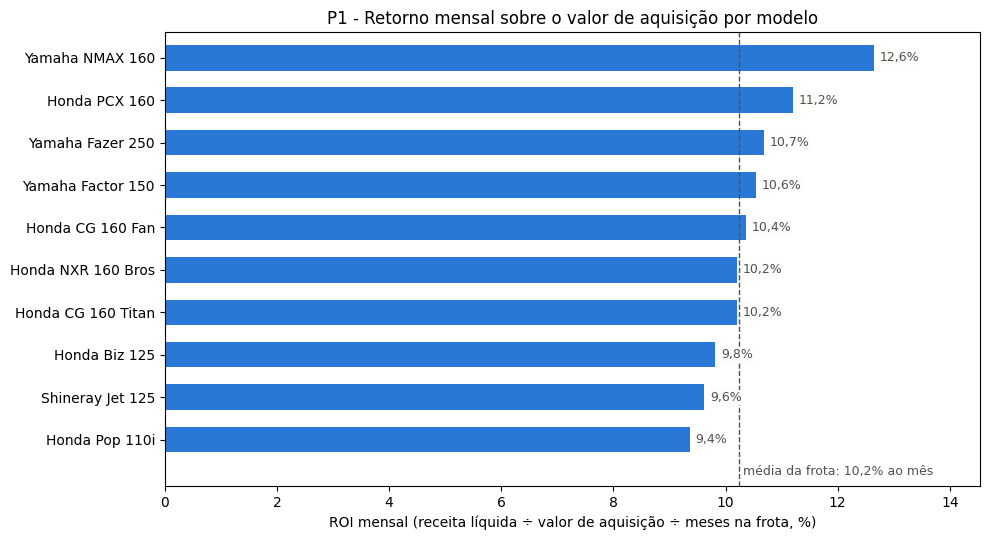

In [14]:
# 14) GRÁFICO 1 (P1) - ROI mensal por modelo de moto
fig, ax = plt.subplots(figsize=(10, 5.5))
dados = por_modelo["roi_mensal_%"].sort_values()      # em % ao mês
barras = ax.barh(dados.index, dados.values, color="#2a78d6", height=0.6)
ax.bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in dados.values], padding=4,
             color="#52514e", fontsize=9, bbox=dict(fc="#fcfcfb", ec="none", pad=0.6))
roi_frota = rentab["receita_liquida"].sum() / (rentab["valor_aquisicao"] * rentab["meses_frota"]).sum() * 100
ax.axvline(roi_frota, color="#52514e", ls="--", lw=1, zorder=1)
ax.text(roi_frota, -0.75, f" média da frota: {roi_frota:.1f}% ao mês".replace(".", ","), color="#52514e", fontsize=9, va="center")
ax.set_ylim(-1.1, len(dados) - 0.4)
ax.set_xlabel("ROI mensal (receita líquida ÷ valor de aquisição ÷ meses na frota, %)")
ax.set_title("P1 - Retorno mensal sobre o valor de aquisição por modelo")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, dados.max() * 1.15)
plt.tight_layout()
plt.show()

## P2 - ocupação e ociosidade (por moto, modelo, filial e período)

In [15]:
# 15) dias alugados por moto e taxa de ocupação
# a locação ocupa a moto da retirada até a devolução real (em andamento: até a devolução prevista), sempre cortada na data de referência
# taxa de ocupação = dias alugados / dias desde a aquisição da moto (a moto só entra na conta depois de comprada)
# locações canceladas ficam de fora (a moto não foi ocupada)
loc_ok["fim"] = loc_ok["data_devolucao_real"].fillna(loc_ok["data_devolucao_prevista"]).clip(upper=data_ref)
loc_ok["dias_alugados"] = (loc_ok["fim"] - loc_ok["data_retirada"]).dt.days

ocup = motos.set_index("id_moto")[["modelo", "filial", "data_aquisicao"]].copy()
ocup["dias_alugados"] = loc_ok.groupby("id_moto")["dias_alugados"].sum()
ocup["dias_periodo"] = (data_ref - ocup["data_aquisicao"]).dt.days
ocup["ocupacao"] = ocup["dias_alugados"] / ocup["dias_periodo"]
print("Motos com ocupação acima de 100%:", (ocup["ocupacao"] > 1).sum())
ocup["ocupacao"].describe().round(3)

Motos com ocupação acima de 100%: 0


count    120.000
mean       0.794
std        0.056
min        0.560
25%        0.774
50%        0.804
75%        0.825
max        0.902
Name: ocupacao, dtype: float64

In [16]:
# 16) ocupação por filial e por modelo
# ocupação do grupo = soma dos dias alugados / soma dos dias de período (motos mais antigas pesam mais, como no ROI do grupo)
def resumo_ocup(g):
    return pd.Series({"motos": len(g), "dias_alugados": g["dias_alugados"].sum(),
                      "ocupacao_%": g["dias_alugados"].sum() / g["dias_periodo"].sum() * 100})

cols_ocup = ["dias_alugados", "dias_periodo"]
ocup_filial = ocup.groupby("filial")[cols_ocup].apply(resumo_ocup)
ocup_modelo = ocup.groupby("modelo")[cols_ocup].apply(resumo_ocup).sort_values("ocupacao_%")
ocupacao_frota = ocup["dias_alugados"].sum() / ocup["dias_periodo"].sum()
print(f"Ocupação da frota: {ocupacao_frota:.1%} | ociosidade: {1 - ocupacao_frota:.1%}")
display(ocup_filial.round(1))
display(ocup_modelo.round(1))

Ocupação da frota: 79.4% | ociosidade: 20.6%


,motos,dias_alugados,ocupacao_%
filial,,,
João Pessoa,68.0,42664.0,79.1
São Paulo,52.0,31961.0,79.9


,motos,dias_alugados,ocupacao_%
modelo,,,
Honda PCX 160,3.0,1326.0,74.4
Shineray Jet 125,7.0,4023.0,78.0
Yamaha Factor 150,17.0,11641.0,78.7
Honda Pop 110i,14.0,9280.0,78.8
Honda Biz 125,19.0,11985.0,79.5
Honda CG 160 Fan,20.0,12726.0,79.7
Honda CG 160 Titan,26.0,14575.0,80.0
Honda NXR 160 Bros,7.0,4608.0,80.4
Yamaha NMAX 160,3.0,1242.0,80.8


In [17]:
# 17) ocupação mês a mês, por filial
# em cada mês: dias alugados dentro do mês / dias em que as motos já estavam na frota
def ocupacao_mensal(ids_motos):
    aquisicao = motos.set_index("id_moto").loc[ids_motos, "data_aquisicao"]
    lo = loc_ok[loc_ok["id_moto"].isin(ids_motos)]
    res = {}
    for mes in pd.period_range("2023-06", "2026-10", freq="M"):
        ini = mes.start_time
        fim = min(mes.end_time.normalize() + pd.Timedelta(days=1), data_ref)
        dias_frota = (fim - aquisicao.clip(lower=ini)).dt.days.clip(lower=0).sum()
        dias_alug = (lo["fim"].clip(upper=fim) - lo["data_retirada"].clip(lower=ini)).dt.days.clip(lower=0).sum()
        res[mes] = dias_alug / dias_frota if dias_frota > 0 else np.nan
    return pd.Series(res)

ocup_mes = pd.DataFrame({
    "Frota toda": ocupacao_mensal(motos["id_moto"]),
    "João Pessoa": ocupacao_mensal(motos.loc[motos["filial"] == "João Pessoa", "id_moto"]),
    "São Paulo": ocupacao_mensal(motos.loc[motos["filial"] == "São Paulo", "id_moto"]),
})
# antes de 2024 a frota tinha menos de 30 motos, então olhamos de 01/2024 em diante
ocup_mes.loc["2024-01":].describe().round(3)

,Frota toda,João Pessoa,São Paulo
count,34.000,34.000,34.000
mean,0.796,0.796,0.798
std,0.020,0.034,0.035
min,0.729,0.744,0.704
25%,0.784,0.775,0.776
50%,0.798,0.789,0.800
75%,0.810,0.812,0.814
max,0.834,0.889,0.864


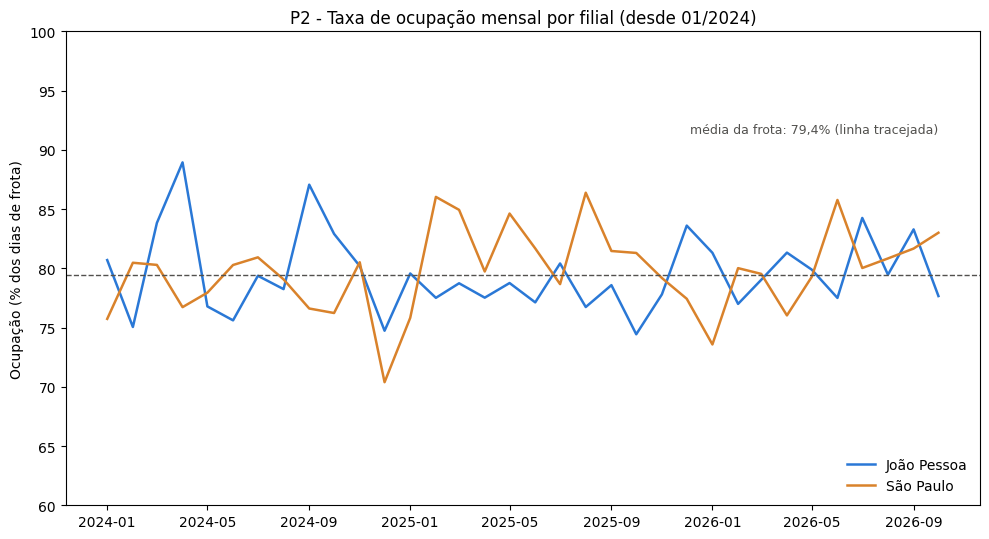

In [18]:
# 18) GRÁFICO 2 (P2) - taxa de ocupação mensal por filial
fig, ax = plt.subplots(figsize=(10, 5.5))
dados = ocup_mes.loc["2024-01":]
x = dados.index.to_timestamp()
ax.plot(x, dados["João Pessoa"] * 100, color="#2a78d6", lw=1.8, label="João Pessoa")
ax.plot(x, dados["São Paulo"] * 100, color="#d9822b", lw=1.8, label="São Paulo")
ax.axhline(ocupacao_frota * 100, color="#52514e", ls="--", lw=1)
ax.text(x[-1], ocupacao_frota * 100 + 12, f"média da frota: {ocupacao_frota * 100:.1f}% (linha tracejada)".replace(".", ","),
        color="#52514e", fontsize=9, ha="right")
ax.set_ylim(60, 100)
ax.set_ylabel("Ocupação (% dos dias de frota)")
ax.set_title("P2 - Taxa de ocupação mensal por filial (desde 01/2024)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## P3 - manutenção (custo, dias parados, receita perdida e idade da frota)

In [19]:
# 19) manutenção por modelo: custo, dias parados, km rodados e receita perdida
# km rodados = soma de (km_devolucao - km_retirada) das locações finalizadas
# receita perdida por parada = dias parados x diária média do modelo
# (é um limite superior: supõe que a moto estaria alugada em todos os dias parados, e a ocupação real é de ~79%)
loc_fin = loc_ok[loc_ok["status_locacao"] == "Finalizada"].copy()
km_rodados = (loc_fin["km_devolucao"] - loc_fin["km_retirada"]).groupby(loc_fin["id_moto"]).sum().rename("km_rodados")
dias_parada = manutencoes.groupby("id_moto")["dias_parada"].sum()
diaria_modelo = loc_ok.merge(motos[["id_moto", "modelo"]], on="id_moto").groupby("modelo")["valor_diaria"].mean()

manut = rentab[["modelo", "filial", "custo_manutencao", "meses_frota"]].join(km_rodados).join(dias_parada)
manut["receita_perdida"] = manut["dias_parada"] * manut["modelo"].map(diaria_modelo)

def resumo_manut(g):
    return pd.Series({"motos": len(g), "custo": g["custo_manutencao"].sum(), "dias_parados": g["dias_parada"].sum(),
                      "custo_por_km": g["custo_manutencao"].sum() / g["km_rodados"].sum(),
                      "custo_por_moto_mes": g["custo_manutencao"].sum() / g["meses_frota"].sum(),
                      "receita_perdida": g["receita_perdida"].sum()})

cols_manut = ["custo_manutencao", "dias_parada", "km_rodados", "meses_frota", "receita_perdida"]
manut_modelo = manut.groupby("modelo")[cols_manut].apply(resumo_manut).sort_values("custo_por_km", ascending=False)
display(manut_modelo.round(3))
print(f"Frota: custo R$ {manut['custo_manutencao'].sum():,.2f} | {manut['dias_parada'].sum():.0f} dias parados | "
      f"receita perdida (limite superior) R$ {manut['receita_perdida'].sum():,.2f} | "
      f"custo por km R$ {manut['custo_manutencao'].sum() / manut['km_rodados'].sum():.3f}")

,motos,custo,dias_parados,custo_por_km,custo_por_moto_mes,receita_perdida
modelo,,,,,,
Honda PCX 160,3.0,12007.34,44.0,0.102,204.994,5097.068
Yamaha NMAX 160,3.0,9008.70,52.0,0.088,178.300,6136.839
Shineray Jet 125,7.0,30108.55,139.0,0.076,177.789,7418.905
Honda Pop 110i,14.0,64615.03,276.0,0.072,166.925,15938.170
Honda NXR 160 Bros,7.0,31853.26,147.0,0.072,169.247,14300.083
Honda CG 160 Titan,26.0,97597.30,406.0,0.069,163.153,34007.764
Honda Biz 125,19.0,74612.69,328.0,0.067,150.641,21862.497
Honda CG 160 Fan,20.0,79114.61,368.0,0.065,150.912,29233.001
Yamaha Factor 150,17.0,72715.82,355.0,0.065,149.650,28194.571


Frota: custo R$ 489,720.05 | 2199 dias parados | receita perdida (limite superior) R$ 172,423.73 | custo por km R$ 0.069


In [20]:
# 20) a manutenção encarece com a idade da moto? e a frota é mais velha que a do setor?
# cuidado: o custo acumulado cresce com o tempo na frota por construção (mesmo problema do ROI acumulado no passo 11)
# por isso olhamos o custo por mês na frota e o custo médio por manutenção em cada faixa de idade da moto
manut["custo_por_mes"] = manut["custo_manutencao"] / manut["meses_frota"]
print("Correlação custo acumulado x meses na frota:", round(manut["custo_manutencao"].corr(manut["meses_frota"]), 2))
print("Correlação custo por mês x meses na frota:", round(manut["custo_por_mes"].corr(manut["meses_frota"]), 2))

man_idade = manutencoes.merge(motos[["id_moto", "data_aquisicao"]], on="id_moto")
man_idade["idade_moto_meses"] = (man_idade["data_manutencao"] - man_idade["data_aquisicao"]).dt.days / 30.44
man_idade["faixa_idade"] = pd.cut(man_idade["idade_moto_meses"], [0, 12, 24, 100],
                                  labels=["até 12 meses", "12 a 24 meses", "mais de 24 meses"])
display(man_idade.groupby("faixa_idade", observed=True).agg(manutencoes=("custo", "size"), custo_medio=("custo", "mean"),
                                                            dias_parada_medio=("dias_parada", "mean")).round(1))

# idade média da frota x idade média das locadoras (ABLA 2025, automóveis e comerciais leves)
bench = pd.read_csv(pasta + "mercado/benchmarks_mercado.csv").set_index("id")
print(f"Idade média da frota: {manut['meses_frota'].mean():.1f} meses | locadoras (ABLA 2025): {bench.loc['B05', 'valor']} meses")

Correlação custo acumulado x meses na frota: 0.62
Correlação custo por mês x meses na frota: -0.06


,manutencoes,custo_medio,dias_parada_medio
faixa_idade,,,
até 12 meses,631,339.5,1.6
12 a 24 meses,464,412.5,1.8
mais de 24 meses,228,369.0,1.7


Idade média da frota: 25.7 meses | locadoras (ABLA 2025): 16.4 meses


In [21]:
# 21) onde está o custo: por tipo de manutenção
por_tipo = manutencoes.groupby("tipo").agg(manutencoes=("custo", "size"), custo_total=("custo", "sum"),
                                           custo_medio=("custo", "mean"), dias_parados=("dias_parada", "sum"))
por_tipo["%_manutencoes"] = por_tipo["manutencoes"] / por_tipo["manutencoes"].sum() * 100
por_tipo["%_custo"] = por_tipo["custo_total"] / por_tipo["custo_total"].sum() * 100
por_tipo = por_tipo.sort_values("custo_total", ascending=False)
por_tipo.round(1)

,manutencoes,custo_total,custo_medio,dias_parados,%_manutencoes,%_custo
tipo,,,,,,
Reparo de acidente,64,137773.1,2152.7,531,4.8,28.1
Troca de pneus,199,98781.7,496.4,295,15.0,20.2
Revisão geral,212,91279.9,430.6,426,16.0,18.6
Troca de óleo,409,46930.8,114.7,220,30.9,9.6
Kit relação,127,36654.5,288.6,195,9.6,7.5
Freios,147,34161.6,232.4,286,11.1,7.0
Elétrica,79,22750.3,288.0,201,6.0,4.6
Bateria,76,17902.0,235.6,29,5.7,3.7
Não informado,10,3486.2,348.6,16,0.8,0.7


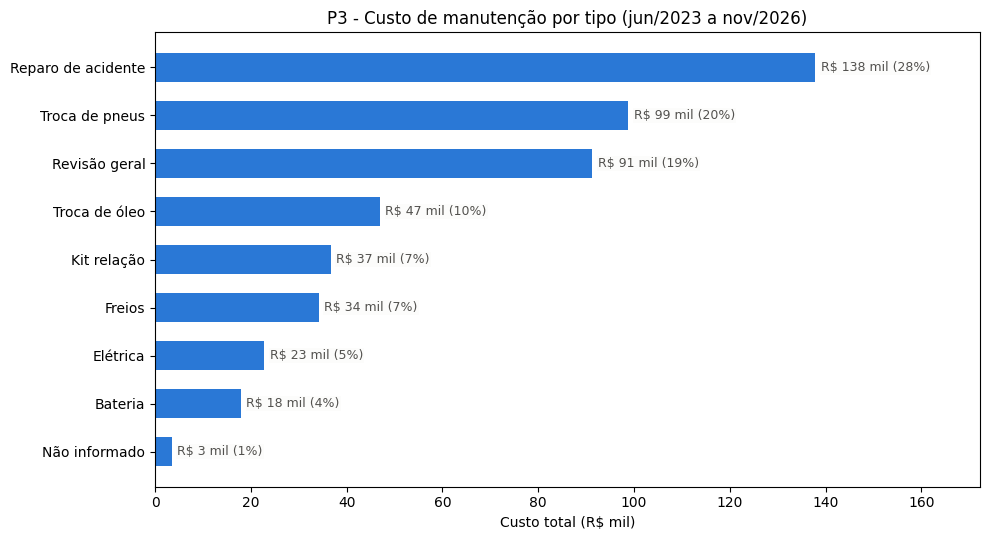

In [22]:
# 22) GRÁFICO 3 (P3) - custo de manutenção por tipo
fig, ax = plt.subplots(figsize=(10, 5.5))
dados = por_tipo["custo_total"].sort_values()
barras = ax.barh(dados.index, dados.values / 1000, color="#2a78d6", height=0.6)
ax.bar_label(barras, labels=[f"R$ {v / 1000:.0f} mil ({v / dados.sum() * 100:.0f}%)" for v in dados.values], padding=4,
             color="#52514e", fontsize=9, bbox=dict(fc="#fcfcfb", ec="none", pad=0.6))
ax.set_xlabel("Custo total (R$ mil)")
ax.set_title("P3 - Custo de manutenção por tipo (jun/2023 a nov/2026)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, dados.max() / 1000 * 1.25)
plt.tight_layout()
plt.show()

## P4 - risco (cancelamento, atraso, inadimplência e furto/roubo)

In [23]:
# 23) cancelamento e atraso na devolução
# cancelamento = locações canceladas / total de locações
# atraso = locações finalizadas devolvidas depois da data prevista / locações finalizadas
# o valor_total das canceladas é 0, então a receita que deixou de entrar é estimada por diária x dias previstos
canceladas = locacoes[locacoes["status_locacao"] == "Cancelada"]
receita_cancelada = (canceladas["valor_diaria"] * (canceladas["data_devolucao_prevista"] - canceladas["data_retirada"]).dt.days).sum()
loc_fin["atraso_dias"] = (loc_fin["data_devolucao_real"] - loc_fin["data_devolucao_prevista"]).dt.days

print(f"Taxa de cancelamento: {len(canceladas) / len(locacoes):.1%} ({len(canceladas)} de {len(locacoes)}) | receita prevista que não entrou: R$ {receita_cancelada:,.2f}")
print(f"Taxa de atraso na devolução: {(loc_fin['atraso_dias'] > 0).mean():.1%} | atraso médio dos atrasados: {loc_fin.loc[loc_fin['atraso_dias'] > 0, 'atraso_dias'].mean():.1f} dias")
for col in ["plano", "filial_retirada"]:
    display((locacoes.groupby(col)["status_locacao"].apply(lambda s: (s == "Cancelada").mean() * 100)).round(1).rename("cancelamento_%").to_frame())

Taxa de cancelamento: 2.8% (116 de 4128) | receita prevista que não entrou: R$ 123,516.50
Taxa de atraso na devolução: 25.0% | atraso médio dos atrasados: 2.3 dias


,cancelamento_%
plano,
Diário,3.1
Mensal,1.9
Semanal,3.0


,cancelamento_%
filial_retirada,
João Pessoa,2.6
São Paulo,3.1


In [24]:
# 24) inadimplência e atraso por plano, forma de pagamento, filial e perfil do cliente
# inadimplência = valor das locações finalizadas com pagamento "Atrasado" ou "Pendente" / valor faturado das finalizadas
# ("Pendente" em locação em andamento não conta: ainda não venceu)
loc_fin["inadimplente"] = loc_fin["status_pagamento"].isin(["Atrasado", "Pendente"])
loc_fin = loc_fin.merge(clientes[["id_cliente", "uf", "categoria_cnh", "data_nascimento"]].rename(columns={"uf": "uf_cliente"}),
                        on="id_cliente", how="left")
idade_cliente = (loc_fin["data_retirada"] - loc_fin["data_nascimento"]).dt.days / 365.25
loc_fin["faixa_etaria"] = pd.cut(idade_cliente, [17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])

perda_inadimplencia = loc_fin.loc[loc_fin["inadimplente"], "valor_total"].sum()
print(f"Inadimplência: R$ {perda_inadimplencia:,.2f} de R$ {loc_fin['valor_total'].sum():,.2f} faturados "
      f"({perda_inadimplencia / loc_fin['valor_total'].sum():.1%})")

def taxas(g):
    return pd.Series({"locacoes": len(g), "atraso_%": (g["atraso_dias"] > 0).mean() * 100,
                      "inadimplencia_%": g.loc[g["inadimplente"], "valor_total"].sum() / g["valor_total"].sum() * 100})

cols_taxas = ["atraso_dias", "inadimplente", "valor_total"]
for col in ["plano", "forma_pagamento", "filial_retirada", "uf_cliente", "categoria_cnh", "faixa_etaria"]:
    display(loc_fin.groupby(col, observed=True)[cols_taxas].apply(taxas).round(1))

Inadimplência: R$ 632,332.30 de R$ 4,963,422.61 faturados (12.7%)


,locacoes,atraso_%,inadimplencia_%
plano,,,
Diário,1724.0,24.6,12.7
Mensal,752.0,24.5,12.2
Semanal,1445.0,25.7,13.7


,locacoes,atraso_%,inadimplencia_%
forma_pagamento,,,
Boleto,392.0,27.3,12.1
Cartão de Crédito,999.0,23.8,13.5
Cartão de Débito,387.0,26.4,15.3
Dinheiro,380.0,24.2,10.7
Não informado,72.0,19.4,5.8
Pix,1691.0,25.3,12.5


,locacoes,atraso_%,inadimplencia_%
filial_retirada,,,
João Pessoa,2214.0,24.8,13.1
São Paulo,1707.0,25.3,12.2


,locacoes,atraso_%,inadimplencia_%
uf_cliente,,,
PB,2445.0,25.2,13.5
SP,1476.0,24.6,11.4


,locacoes,atraso_%,inadimplencia_%
categoria_cnh,,,
A,2783.0,24.9,12.0
AB,1138.0,25.2,14.4


,locacoes,atraso_%,inadimplencia_%
faixa_etaria,,,
18-25,194.0,21.6,10.3
26-35,780.0,25.5,11.9
36-45,1071.0,24.9,16.1
46-55,820.0,23.9,12.7
56+,741.0,25.6,10.7


In [25]:
# 25) furto e roubo (base real da M2)
# taxa = motos furtadas ou roubadas / motos-ano expostas x 1.000
# motos-ano = tempo de cada moto na frota (aquisição até a data de referência) em anos
# é uma aproximação: não tira da conta o tempo depois do furto, então a taxa real tende a ser maior
m2_motos = pd.read_csv(pasta + "m2/motos.csv")
m2_loc = pd.read_csv(pasta + "m2/locacoes.csv")
m2_motos["data_aquisicao"] = pd.to_datetime(m2_motos["data_aquisicao"], format="%d/%m/%Y")
for col in ["data_devolucao_prevista", "data_devolucao_real"]:
    m2_loc[col] = pd.to_datetime(m2_loc[col], format="%d/%m/%Y")

furtadas = m2_motos["status"].str.contains("Furtada|Roubada").sum()
motos_ano = ((data_ref - m2_motos["data_aquisicao"]).dt.days / 365).sum()
taxa_m2 = furtadas / motos_ano * 1000
print(f"M2: {furtadas} de {len(m2_motos)} motos furtadas ou roubadas em {motos_ano:.1f} motos-ano = {taxa_m2:.0f} por 1.000 motos-ano")
print(f"Referência SSP-SP + SENATRAN: estado de SP {bench.loc['B20', 'valor']} | capital {bench.loc['B21', 'valor']} por 1.000 motos-ano "
      f"-> M2 é {taxa_m2 / bench.loc['B21', 'valor']:.0f}x a capital")

# receita contratual que deixou de entrar nos contratos interrompidos: dias que faltavam x diária (limite superior)
interrompidas = m2_loc[m2_loc["status_locacao"] == "Interrompida (furto/roubo)"].copy()
interrompidas["receita_futura"] = (interrompidas["data_devolucao_prevista"] - interrompidas["data_devolucao_real"]).dt.days * interrompidas["valor_diaria"]
print(f"Contratos interrompidos por furto/roubo: {len(interrompidas)} de {len(m2_loc)} | receita contratual futura perdida: R$ {interrompidas['receita_futura'].sum():,.2f}")

M2: 6 de 10 motos furtadas ou roubadas em 15.3 motos-ano = 392 por 1.000 motos-ano
Referência SSP-SP + SENATRAN: estado de SP 4.39 | capital 7.77 por 1.000 motos-ano -> M2 é 50x a capital
Contratos interrompidos por furto/roubo: 5 de 15 | receita contratual futura perdida: R$ 232,828.20


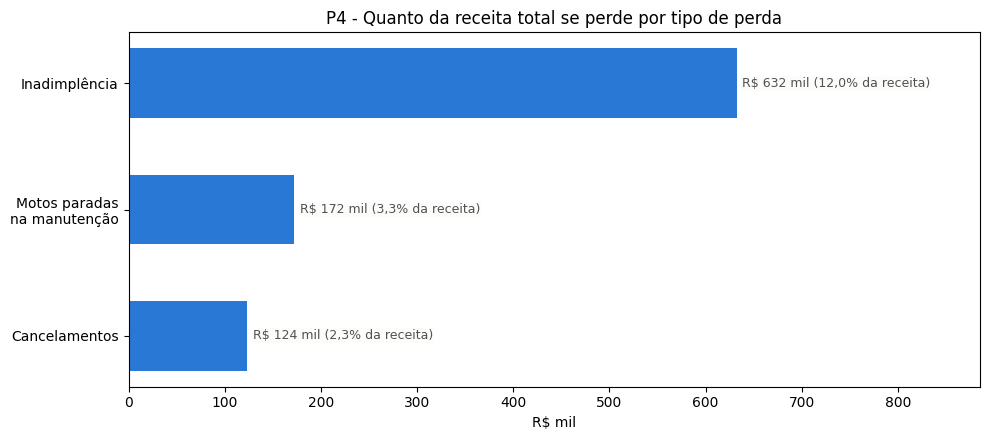

In [26]:
# 26) GRÁFICO 4 (P4) - quanto da receita se perde (base hidratada)
# inadimplência = pagamento atrasado ou pendente nas finalizadas | paradas = limite superior | cancelamentos = receita prevista
perdas = pd.Series({"Inadimplência": perda_inadimplencia,
                    "Motos paradas\nna manutenção": manut["receita_perdida"].sum(),
                    "Cancelamentos": receita_cancelada}).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(perdas.index, perdas.values / 1000, color="#2a78d6", height=0.55)
ax.bar_label(barras, labels=[f"R$ {v / 1000:.0f} mil ({v / receita_total * 100:.1f}% da receita)".replace(".", ",") for v in perdas.values],
             padding=4, color="#52514e", fontsize=9, bbox=dict(fc="#fcfcfb", ec="none", pad=0.6))
ax.set_xlabel("R$ mil")
ax.set_title("P4 - Quanto da receita total se perde por tipo de perda")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, perdas.max() / 1000 * 1.4)
plt.tight_layout()
plt.show()

## P5 - clientes (perfil, recorrência e sazonalidade)

In [27]:
# 27) recorrência e concentração da receita
# só entram os clientes com pelo menos uma locação não cancelada
por_cliente = loc_ok.groupby("id_cliente").agg(locacoes=("id_locacao", "size"), receita=("valor_total", "sum"))
recorrentes = (por_cliente["locacoes"] >= 2).mean()
top20 = por_cliente["receita"].nlargest(int(len(por_cliente) * 0.2)).sum() / por_cliente["receita"].sum()
print(f"Clientes com locação: {len(por_cliente)} | recorrência (2 ou mais locações): {recorrentes:.1%}")
print(f"Os 20% de clientes que mais gastam respondem por {top20:.1%} da receita")
por_cliente["locacoes"].describe().round(1)

Clientes com locação: 561 | recorrência (2 ou mais locações): 85.6%
Os 20% de clientes que mais gastam respondem por 54.2% da receita


count    561.0
mean       7.2
std        6.6
min        1.0
25%        2.0
50%        5.0
75%       10.0
max       42.0
Name: locacoes, dtype: float64

In [28]:
# 28) receita por perfil: plano, UF, categoria da CNH e faixa etária
loc_perfil = loc_ok.merge(clientes[["id_cliente", "uf", "categoria_cnh", "data_nascimento"]], on="id_cliente", how="left")
idade_cliente = (loc_perfil["data_retirada"] - loc_perfil["data_nascimento"]).dt.days / 365.25
loc_perfil["faixa_etaria"] = pd.cut(idade_cliente, [17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])

def resumo_perfil(g):
    return pd.Series({"locacoes": len(g), "clientes": g["id_cliente"].nunique(), "receita": g["valor_total"].sum(),
                      "ticket_medio": g["valor_total"].mean()})

for col in ["plano", "uf", "categoria_cnh", "faixa_etaria"]:
    tabela = loc_perfil.groupby(col, observed=True)[["id_cliente", "valor_total"]].apply(resumo_perfil)
    tabela["%_locacoes"] = tabela["locacoes"] / tabela["locacoes"].sum() * 100
    tabela["%_receita"] = tabela["receita"] / tabela["receita"].sum() * 100
    display(tabela.round(1))

,locacoes,clientes,receita,ticket_medio,%_locacoes,%_receita
plano,,,,,,
Diário,1726.0,476.0,646419.5,374.5,43.0,12.2
Mensal,819.0,360.0,3037412.2,3708.7,20.4,57.5
Semanal,1467.0,437.0,1602945.0,1092.7,36.6,30.3


,locacoes,clientes,receita,ticket_medio,%_locacoes,%_receita
uf,,,,,,
PB,2500.0,347.0,3298409.0,1319.4,62.3,62.4
SP,1512.0,214.0,1988367.7,1315.1,37.7,37.6


,locacoes,clientes,receita,ticket_medio,%_locacoes,%_receita
categoria_cnh,,,,,,
A,2845.0,401.0,3666217.2,1288.7,70.9,69.3
AB,1167.0,160.0,1620559.4,1388.7,29.1,30.7


,locacoes,clientes,receita,ticket_medio,%_locacoes,%_receita
faixa_etaria,,,,,,
18-25,197.0,41.0,239250.6,1214.5,5.3,4.9
26-35,796.0,134.0,1053382.0,1323.3,21.6,21.7
36-45,1095.0,156.0,1423154.7,1299.7,29.7,29.3
46-55,838.0,145.0,1124615.0,1342.0,22.7,23.2
56+,760.0,120.0,1016299.7,1337.2,20.6,20.9


In [29]:
# 29) sazonalidade: locações e receita por mês de retirada, por moto na frota
# a frota cresceu de 1 para 120 motos até 12/2025, então a contagem bruta de locações só reflete esse crescimento
# por isso dividimos pelo nº de motos já compradas no mês e usamos só os anos completos (2024 e 2025)
loc_ok["mes"] = loc_ok["data_retirada"].dt.to_period("M")
mensal = loc_ok.groupby("mes").agg(locacoes=("id_locacao", "size"), receita=("valor_total", "sum"))
mensal["motos"] = [(motos["data_aquisicao"] <= mes.end_time).sum() for mes in mensal.index]
mensal["locacoes_por_moto"] = mensal["locacoes"] / mensal["motos"]
mensal["receita_por_moto"] = mensal["receita"] / mensal["motos"]

completos = mensal.loc["2024-01":"2025-12"]
sazon = completos.assign(ano=completos.index.year, mes=completos.index.month).pivot(
    index="mes", columns="ano", values=["locacoes_por_moto", "receita_por_moto"])
display(sazon.round(2))
# se existisse sazonalidade, os meses fortes de 2024 seriam fortes também em 2025 (correlação entre os dois anos alta)
print("Correlação entre 2024 e 2025 (locações por moto, mês a mês):", round(sazon["locacoes_por_moto"][2024].corr(sazon["locacoes_por_moto"][2025]), 2))
print("Correlação entre 2024 e 2025 (receita por moto, mês a mês):", round(sazon["receita_por_moto"][2024].corr(sazon["receita_por_moto"][2025]), 2))

locacoes_por_moto       receita_por_moto         
ano              2024  2025             2024     2025
mes                                                  
1                1.35  1.46          1607.40  2105.66
2                1.39  1.15          2066.63  1278.56
3                1.39  1.14          1617.12  1682.49
4                0.90  1.37          1815.41  1701.58
5                1.24  1.25          1325.40  1652.18
6                1.25  1.33          1846.21  1902.94
7                1.33  1.25          1866.41  1404.43
8                1.28  1.36          1670.52  1999.80
9                1.10  1.29          1441.81  1477.85
10               1.16  1.41          1684.04  1661.38
11               1.31  1.41          1741.43  1922.27
12               1.44  1.42          1572.44  1590.65

Correlação entre 2024 e 2025 (locações por moto, mês a mês): -0.22
Correlação entre 2024 e 2025 (receita por moto, mês a mês): -0.22


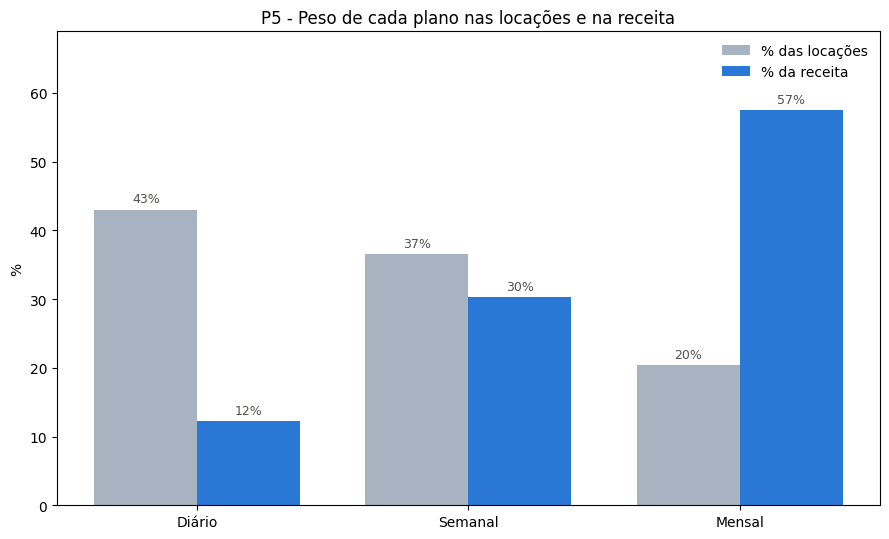

In [30]:
# 30) GRÁFICO 5 (P5) - peso de cada plano nas locações e na receita
plano = loc_perfil.groupby("plano")["valor_total"].agg(["size", "sum"]).loc[["Diário", "Semanal", "Mensal"]]
pct_loc = plano["size"] / plano["size"].sum() * 100
pct_rec = plano["sum"] / plano["sum"].sum() * 100
x = np.arange(len(plano))
largura = 0.38
fig, ax = plt.subplots(figsize=(9, 5.5))
b1 = ax.bar(x - largura / 2, pct_loc.values, largura, color="#a8b3c2", label="% das locações")
b2 = ax.bar(x + largura / 2, pct_rec.values, largura, color="#2a78d6", label="% da receita")
for barras in (b1, b2):
    ax.bar_label(barras, labels=[f"{v:.0f}%" for v in barras.datavalues], padding=3, color="#52514e", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(plano.index)
ax.set_ylabel("%")
ax.set_ylim(0, max(pct_loc.max(), pct_rec.max()) * 1.2)
ax.set_title("P5 - Peso de cada plano nas locações e na receita")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## P6 - posicionamento frente ao mercado (preço, alcance geográfico, crescimento e mix)

In [31]:
# 31) preço: diária média x 7 (preço semanal equivalente) por plano, comparado ao mercado
# comparação justa: só a Yamaha Factor 150, o mesmo modelo anunciado pela BluStar (R$ 343 a 364 por semana, 08/2026)
preco = loc_ok.merge(motos[["id_moto", "modelo"]], on="id_moto")
preco_plano = preco.groupby("plano")["valor_diaria"].mean() * 7
preco_factor = preco[preco["modelo"] == "Yamaha Factor 150"].groupby("plano")["valor_diaria"].mean() * 7
blustar_mensal, blustar_anual = bench.loc["B22", "valor"], bench.loc["B23", "valor"]
mottu_semana = bench.loc["B24", "valor"] * 7                      # R$ 18 por dia, motos de 110 cc
m2_semana = m2_loc.loc[m2_loc["plano"] == "Minha Moto 28 meses", "valor_diaria"].mean() * 7

comparacao = pd.DataFrame({"todas as motos (R$/semana)": preco_plano, "Factor 150 (R$/semana)": preco_factor})
comparacao["Factor 150 x BluStar mensal (%)"] = (comparacao["Factor 150 (R$/semana)"] / blustar_mensal - 1) * 100
display(comparacao.loc[["Diário", "Semanal", "Mensal"]].round(1))
print(f"Referências (R$/semana): BluStar Factor 150 {blustar_anual:.0f} a {blustar_mensal:.0f} | Mottu (entrada) {mottu_semana:.0f} | M2 (plano de 28 meses) {m2_semana:.0f}")

,todas as motos (R$/semana),Factor 150 (R$/semana),Factor 150 x BluStar mensal (%)
plano,,,
Diário,611.0,630.0,73.1
Semanal,525.3,535.8,47.2
Mensal,434.5,441.0,21.2


Referências (R$/semana): BluStar Factor 150 343 a 364 | Mottu (entrada) 126 | M2 (plano de 28 meses) 449


In [32]:
# 32) alcance geográfico: clientes por 10 mil motos registradas no município (SENATRAN 09/2026)
# a ligação é feita pelo nome da cidade em maiúsculas e sem acento
def sem_acento(texto):
    return unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().upper().strip()

sen_mun = pd.read_csv(pasta + "mercado/senatran_frota_motos_municipios_sp_pb.csv")
sen_uf = pd.read_csv(pasta + "mercado/senatran_frota_motos_uf.csv")
clientes_ativos = clientes[clientes["id_cliente"].isin(loc_ok["id_cliente"])].copy()
clientes_ativos["municipio"] = clientes_ativos["cidade"].map(sem_acento)

penetracao = (clientes_ativos.groupby(["uf", "municipio"]).size().rename("clientes").reset_index()
              .merge(sen_mun, on=["uf", "municipio"], how="left"))
penetracao["clientes_por_10mil_motos"] = penetracao["clientes"] / penetracao["motos_total"] * 10000
print("Clientes sem cidade informada (fora da conta):", penetracao.loc[penetracao["motos_total"].isna(), "clientes"].sum())
display(penetracao.sort_values("clientes", ascending=False).head(8)
        [["uf", "municipio", "clientes", "motos_total", "pct_motos_na_frota", "clientes_por_10mil_motos"]].round(1))
display(sen_uf[sen_uf["regiao_uf"].isin(["Paraíba", "São Paulo", "Brasil"])][["regiao_uf", "motos_total", "pct_motos_na_frota"]])

Clientes sem cidade informada (fora da conta): 11


,uf,municipio,clientes,motos_total,pct_motos_na_frota,clientes_por_10mil_motos
2,PB,JOAO PESSOA,246,169690.0,32.6,14.5
8,SP,SAO PAULO,145,1715050.0,16.9,0.8
5,SP,GUARULHOS,37,156901.0,17.9,2.4
4,PB,SANTA RITA,34,26522.0,44.9,12.8
0,PB,BAYEUX,33,17553.0,40.8,18.8
1,PB,CABEDELO,29,11299.0,30.6,25.7
7,SP,OSASCO,26,108639.0,20.9,2.4
6,SP,NAO INFORMADO,6,NaN,NaN,NaN


,regiao_uf,motos_total,pct_motos_na_frota
0,Brasil,38315400,28.74
14,Paraíba,862654,45.69
23,São Paulo,7662639,21.18


In [33]:
# 33) crescimento da frota e mix de modelos
# 2023 é parcial (a primeira moto foi comprada em 06/2023)
frota_ano = motos.groupby(motos["data_aquisicao"].dt.year).size().rename("motos_compradas").to_frame()
frota_ano["frota_no_fim_do_ano"] = frota_ano["motos_compradas"].cumsum()
frota_ano["crescimento_%"] = frota_ano["frota_no_fim_do_ano"].pct_change() * 100
display(frota_ano.round(1))
print(f"Referência: motos nas frotas das locadoras do Brasil cresceram {bench.loc['B03', 'valor']}% em 2025 (ABLA)")

mix = motos["modelo"].value_counts(normalize=True).mul(100).rename("%_da_frota")
display(mix.round(1).to_frame())
print(f"CG 160 (Titan + Fan): {mix[['Honda CG 160 Titan', 'Honda CG 160 Fan']].sum():.1f}% da frota | na M2 é 100% CG 160")

,motos_compradas,frota_no_fim_do_ano,crescimento_%
data_aquisicao,,,
2023,25,25,NaN
2024,50,75,200.0
2025,45,120,60.0


Referência: motos nas frotas das locadoras do Brasil cresceram 81.6% em 2025 (ABLA)


,%_da_frota
modelo,
Honda CG 160 Titan,21.7
Honda CG 160 Fan,16.7
Honda Biz 125,15.8
Yamaha Factor 150,14.2
Honda Pop 110i,11.7
Honda NXR 160 Bros,5.8
Shineray Jet 125,5.8
Yamaha Fazer 250,3.3
Yamaha NMAX 160,2.5


CG 160 (Titan + Fan): 38.3% da frota | na M2 é 100% CG 160


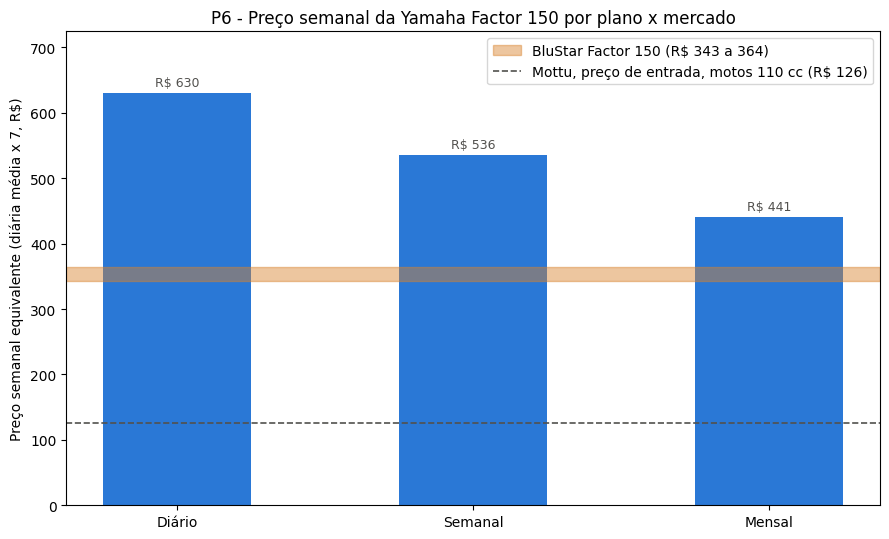

In [34]:
# 34) GRÁFICO 6 (P6) - preço semanal da Yamaha Factor 150 por plano x mercado
dados = preco_factor.loc[["Diário", "Semanal", "Mensal"]]
fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.bar(dados.index, dados.values, color="#2a78d6", width=0.5)
ax.bar_label(barras, labels=[f"R$ {v:.0f}" for v in dados.values], padding=3, color="#52514e", fontsize=9)
ax.axhspan(blustar_anual, blustar_mensal, color="#d9822b", alpha=0.45, label=f"BluStar Factor 150 (R$ {blustar_anual:.0f} a {blustar_mensal:.0f})")
ax.axhline(mottu_semana, color="#52514e", ls="--", lw=1.2, label=f"Mottu, preço de entrada, motos 110 cc (R$ {mottu_semana:.0f})")
ax.legend(loc="upper right", frameon=True)
ax.set_ylabel("Preço semanal equivalente (diária média x 7, R$)")
ax.set_ylim(0, dados.max() * 1.15)
ax.set_title("P6 - Preço semanal da Yamaha Factor 150 por plano x mercado")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## Primeiras conclusões (para validação)

**Base**
- Volumes da base tratada: 120 motos, 700 clientes, 4.128 locações e 1.323 manutenções.
- Período: as locações vão de 30/06/2023 a 01/11/2026 (cerca de 40 meses). As motos foram compradas entre 06/2023 e 12/2025.
- Relação entre as tabelas: nenhuma chave órfã. Cada moto tem de 8 a 65 locações e de 4 a 19 manutenções. 137 clientes estão cadastrados mas nunca alugaram.

**P1 - Rentabilidade**
- Receita total de R$ 5,29 milhões, com ticket médio de R$ 1.317,74 por locação.
- O ROI acumulado depende quase só da idade da moto (correlação de 0,96 com os meses na frota). Por isso a comparação usa o **ROI mensal**.
- A frota devolve em média 10,2% do valor de compra por mês. O melhor modelo é o Yamaha NMAX 160 (12,6% ao mês) e os piores são o Honda Pop 110i (9,4%) e o Shineray Jet 125 (9,6%).
- As duas filiais praticamente empatam no ROI mensal (João Pessoa 10,2% e São Paulo 10,3%). João Pessoa fatura mais porque tem mais motos (68 contra 52).

**P2 - Ocupação e ociosidade**
- A frota fica alugada em **79,4%** dos dias, ou seja, cerca de **1 dia em cada 5 (20,6%) a moto está parada**. Moto a moto, a ocupação vai de 56,0% a 90,2%.
- A ociosidade **não se concentra** em uma filial ou modelo: João Pessoa 79,1% e São Paulo 79,9%. Os modelos com 7 motos ou mais ficam entre 78,0% e 80,4%. Os extremos (Honda PCX 160 com 74,4% e Yamaha Fazer 250 com 81,4%) têm só 3 e 4 motos, então não dá para concluir nada deles.
- Mês a mês (desde 01/2024) a ocupação da frota oscila pouco: média de 79,6%, entre 72,9% e 83,4%.

**P3 - Manutenção**
- A manutenção custou R$ 489,7 mil (R$ 0,069 por km rodado) e deixou as motos paradas por 2.199 dias. Se todos esses dias fossem de motos alugadas, a receita perdida seria de até R$ 172,4 mil (limite superior, porque a ocupação real é de 79%).
- **Não há sinal de que a manutenção encareça com a idade da moto.** O custo acumulado correlaciona com os meses na frota (0,62), mas isso é por construção. O custo por mês na frota tem correlação de -0,06 com a idade, e o custo médio por manutenção fica estável entre as faixas de idade (R$ 340, R$ 413 e R$ 369).
- A frota tem 25,7 meses de idade média, contra 16,4 meses das locadoras do setor (ABLA, automóveis). A frota é mais velha, mas nos dados isso não aparece como custo maior.
- O custo se concentra em poucos eventos: **reparo de acidente é 4,8% das manutenções e 28,1% do custo** (R$ 137,8 mil, 531 dias parados). Troca de pneus (20,2%) e revisão geral (18,6%) vêm depois. Troca de óleo é 30,9% das manutenções, mas só 9,6% do custo.
- Por modelo, o custo por km é maior no Honda PCX 160 (R$ 0,102) e no Yamaha NMAX 160 (R$ 0,088), mas ambos têm só 3 motos.

**P4 - Risco**
- Cancelamento: 2,8% das locações (116), o que equivale a R$ 123,5 mil de receita prevista que não entrou. O plano mensal cancela menos (1,9%, contra 3,1% do diário e 3,0% do semanal).
- Atraso na devolução: 25,0% das locações finalizadas, com atraso médio de 2,3 dias entre as atrasadas.
- Inadimplência: R$ 632,3 mil, ou **12,7% do faturado** nas locações finalizadas (12,0% da receita total). É a maior perda da base hidratada, bem acima das paradas por manutenção (3,3%) e dos cancelamentos (2,3%).
- Atraso e inadimplência são **parecidos em todos os grupos** (atraso entre 22% e 27%; inadimplência entre 10% e 16%). Os maiores valores aparecem em clientes de 36 a 45 anos (16,1%), no cartão de débito (15,3%) e na CNH AB (14,4%). Essas diferenças são pequenas e não foram testadas estatisticamente, então não servem como regra de negócio.
- **Furto e roubo (M2, dados reais):** 6 das 10 motos foram furtadas ou roubadas, o que dá **392 por 1.000 motos-ano**, cerca de **50 vezes** a taxa da capital paulista (7,77). 5 dos 15 contratos foram interrompidos por isso, e a receita contratual futura perdida chega a R$ 232,8 mil (limite superior). É a perda mais pesada da operação real, mesmo com só 10 motos.

**P5 - Clientes**
- 561 clientes alugaram pelo menos uma vez. **85,6% são recorrentes** (2 ou mais locações), com mediana de 5 locações por cliente.
- Os 20% de clientes que mais gastam respondem por **54,2%** da receita.
- O **plano mensal** é 20,4% das locações e 57,5% da receita (ticket de R$ 3.709). O diário é 43,0% das locações e só 12,2% da receita (ticket de R$ 375).
- Paraíba e São Paulo têm o mesmo ticket (R$ 1.319 e R$ 1.315), e a Paraíba traz 62,4% da receita. Clientes com CNH AB têm ticket 8% maior (R$ 1.389 contra R$ 1.289). Dos 26 anos em diante o ticket é parecido (R$ 1.300 a R$ 1.342), e o grupo de 18 a 25 anos é só 5,3% das locações.
- **Não há sazonalidade estável.** Os meses fortes de 2024 não são os de 2025 (correlação de -0,22 entre os dois anos). O crescimento mensal das locações vem do aumento da frota (de 1 para 120 motos), não de época do ano.

**P6 - Posicionamento frente ao mercado**
- **Preço:** na Yamaha Factor 150, o preço semanal equivalente é R$ 630 (diário), R$ 536 (semanal) e R$ 441 (mensal), contra R$ 343 a 364 da BluStar. Mesmo o plano mensal fica **21% acima** do mercado (o diário, 73%). O preço de entrada da Mottu (R$ 126 por semana) é de motos de 110 cc e não é comparável. O plano da M2 (R$ 449 por semana) inclui a transferência da moto ao cliente no fim de 28 meses.
- **Alcance:** João Pessoa tem 14,5 clientes por 10 mil motos registradas e São Paulo só 0,8 (cerca de 17 vezes menos), embora as motos sejam 32,6% da frota de João Pessoa e 16,9% da de São Paulo. As cidades vizinhas de João Pessoa têm penetração parecida (Cabedelo 25,7, Bayeux 18,8, Santa Rita 12,8), e as da Grande São Paulo ficam em 2,4 (Guarulhos e Osasco).
- **Crescimento:** a frota passou de 25 motos (2023) para 75 (2024) e 120 (2025). Em 2025 cresceu 60%, abaixo dos +81,6% das motos nas frotas das locadoras do país (ABLA).
- **Mix:** a Honda CG 160 (Titan e Fan) é 38,3% da frota, alinhada ao modelo mais vendido do país. Na M2 é 100% CG 160.

**Limitações**
- A base principal foi gerada por IA. A uniformidade de ocupação, atraso e inadimplência entre filiais, modelos e perfis pode vir da forma como os dados foram gerados, e não do negócio.
- Modelos com 3 ou 4 motos (Honda PCX 160, Yamaha NMAX 160 e Yamaha Fazer 250) não permitem conclusões.
- A M2 tem só 10 motos e 15 contratos. A taxa de furto/roubo usa o tempo de cada moto na frota até a data de referência, sem descontar o período depois do furto, e compara ocorrências de 2025 (SSP-SP) com a frota de 09/2026 (SENATRAN).
- A receita perdida por paradas e por furto/roubo é um limite superior, e a receita dos cancelamentos é estimada por diária x dias previstos.